# Topic Modeling
### Bert Sentence Embedding, LDA, and K-means Clustering

#### Concatenate the sentence embeddings with LDA, use an autoencoder to get the latent representation and perform K-means to perform clustering on the data

#### After the sentences have been assigned to their clusters, we can extract the candidate topics for each cluster using tokens of it's sentences

In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

In [ ]:
% cd /content/drive/My Drive/Thesis_colab

In [ ]:
! pip install transformers
! pip install pandas
! pip install torch
! pip install nltk
! pip install gensim
! pip install matplotlib
! pip install umap-learn
! pip install wordcloud
! pip install sklearn
! pip install tqdm
! pip install stop_words
! pip install xlrd
! pip install langdetect
! pip install openpyxl
! pip install sentence_transformers
! pip install pyLDAvis
! pip install pickle5


In [ ]:
# install ocra to save figures using plotly
!pip install plotly==4.7.1
!wget https://github.com/plotly/orca/releases/download/v1.2.1/orca-1.2.1-x86_64.AppImage -O /usr/local/bin/orca
!chmod +x /usr/local/bin/orca
!apt-get update
!apt-get install xvfb libgtk2.0-0 libgconf-2-4


In [2]:
import nltk
import numpy as np
import statistics
from sklearn.decomposition import PCA
from collections import Counter
import pandas as pd

In [ ]:
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('wordnet')

### 1. Reading and preprocessing the data

In [3]:
from utilities.document_preprocessing import preprocess_documents

#### The preprocess_document function reads the sentences from the file and generates tokens from each sentences.

In [4]:
Verbose = False

In [6]:
# Read new data file
file = "data/PMP_Skills_Matching_Pilot_2018_2019_small.xlsx"
file = "/home/anum/Downloads/25828_32915_compressed_Train_rev1.csv/Train_rev1.csv"
file = "data/job_small.xlsx"


ids, sentences, token_lists = preprocess_documents(file, verbose = Verbose, 
                                                   #dr = "output/preprocessed_data/job/20000/",
                                                   subset = 500)


ids = list (ids)
num_docs = len(ids)


Reading the file
Shortest Objective is of length  20
Largest Objective is of length  962
Allowed length according to data is 492 but since it is greater than 500, reducing it to 500
Preprocessing raw texts 

0
Dropped 0 entries with non english text

 Preprocessing raw texts. Done!


In [ ]:
#read the previously processed data

data_file = "data/flask/use_this_data.pkl"
#data_file = "output/11.09.2020/mercks_objectives/use_this_data_merck_unique.pkl"
data_file = "output/preprocessed_data/job/use_this_data_50000_job.pkl"

import pickle5 as pickle

with (open(data_file, "rb")) as openfile:
    data = pickle.load(openfile)



In [7]:
len(sentences)

499

## 2. Topic Modeling

In [8]:
from models.topic_model import Topic_Model

[nltk_data] Downloading package wordnet to /home/anum/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


#### The topic_Model class does the follow
- Extract sentence embeddings for all sentences (Local features)
- get topic distribution for each sentence using LDA/LSI
- concatenate both and learn the latent representation using an auto-encoder
- cluster the latent representation into K clusters

##### Available embeddings: ['xlnet', 'electra', 'xlm', 'bert','albert', 'bert-sent','roberta-sent', 'distilbert-sent']
where '-sent' corresponds to the sentence transformer library and all the other models belong to hugging face library.

Attention vectors would only be available with the models from hugging face

In [9]:
# define the numbe of clusters
k = 5

In [10]:
# Define the topic model object
TopicModelObject = Topic_Model(base = None, k = k, verbose = False, embedding = 'bert-sent',
                               saved_embedding_dir = None,
                               embedding_batch_size = 500, use_AE= False)

In [ ]:
# for Colab
# Define the topic model object
TopicModelObject = Topic_Model( k = k, verbose = Verbose, embedding = 'bert', lamda = 15,
                               saved_embedding_dir = None, embedding_batch_size = 100, use_AE= False)

In [11]:
# Fit the topic model
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    warnings.warn("deprecated", DeprecationWarning)


    TopicModelObject.fit(sentences, token_lists, epoch = 5)


 Getting vector representations for bert-sent 
cpu
Our final sentence embedding vector of shape: 499 768
Clustering. Done!
Silhouette Score for the clusters is
0.11625549360316763


In [12]:
TopicModelObject.vec

{'EMBEDDING': array([[-0.40622944,  0.77418911,  1.39469457, ..., -0.78426617,
         -1.43374658,  0.37145606],
        [-0.09178708,  0.66671765,  0.91217631, ..., -0.79130208,
         -0.29064697, -0.20870943],
        [-0.85821277,  1.08339274,  0.76265198, ..., -0.93368542,
         -0.60583442,  0.5403626 ],
        ...,
        [-0.62381458,  0.45792878,  1.05149579, ..., -0.28651509,
         -0.7121495 ,  0.08587635],
        [-0.15659869,  0.87616682,  1.34594035, ..., -0.63433743,
         -0.48491687, -0.2631835 ],
        [ 0.13375108,  0.72460926,  1.2610569 , ...,  0.03687527,
         -0.3396391 , -0.05582535]]),
 'attention': None,
 'embedding_tokens': []}

## 3. Analysis on learned features

#### Preprocessing (Dimensionality Reduction) for visualization

Perform Dimensionality reduction on the learned features using the following steps:

1) Merge all the vectors of each employee into one by taking average

2) Assign the class label to each employee based on argmax on label counts.

3) Further compress the average feature vector into 2d/3d space for visualization.

In [ ]:
# Getting feature vectors and cluster labels assigned by the model
if TopicModelObject.method == 'LDA' or TopicModelObject.method =='LSI':
    feature_vector = TopicModelObject.vec[TopicModelObject.method]
    # for each sentence, find out the cluster it belongs to
    cluster_label_per_document = np.argmax(np.array(feature_vector), axis=1)
else:
    cluster_label_per_document = np.array(TopicModelObject.cluster_model.labels_)
    feature_vector = TopicModelObject.vec[TopicModelObject.method]
    feature_vector = feature_vector.cpu().numpy()
    

unique_ids = list(set(ids))
num_employee = len(unique_ids)

In [ ]:
# Create place holder for the analysis
averaged_employee_features = pd.DataFrame(None, index=pd.Index(unique_ids, name='Employee id'),
                                          columns=pd.Index(
                                              ['feature_vector', 'cluster', 'feature_vector_2d', 'feature_vector_3d'],
                                              name='Compressed_features'))

In [ ]:
# get the indices of all objectives/documents/sentence for each employee (for later use)
employee_objective_indices = dict()
for employee in unique_ids:
    employee_indices = [i for i, e in enumerate(ids) if (ids[i] == employee) ]
    employee_objective_indices[employee] = employee_indices

In [ ]:
# 1 & 2 take average of all feature vectors belonging to an employee and assigning cluster label by taking the mode

for employee in unique_ids:
    #get all feature vectors belonging to an employee
    feature_vector_per_employee = feature_vector[employee_objective_indices[employee]]
    # get label for all feature vectors belonging to that employee
    clusters_per_employee = cluster_label_per_document[employee_objective_indices[employee]]  
    
    #take mean of all feature vectors
    averaged_employee_features['feature_vector'][employee] = np.mean(feature_vector_per_employee, axis=0)
    
    # pick the label with most occurance for that employee
    c = Counter(clusters_per_employee)
    averaged_employee_features['cluster'][employee] = c.most_common(1)[0][0]
    
averaged_employee_features

In [ ]:
# 3) doing dimensionality reduction into 2d/3d Space
from sklearn.manifold import TSNE

#todo: find a more permanent solution for this
# panda returns a array of array for the column feature vector. Converting from array of array to 2d array
feature_vector_ = np.stack(averaged_employee_features['feature_vector'].to_numpy())

# reduce dimension of feature vectors into 2
feature_vector_2d = TSNE(n_components=2).fit_transform(feature_vector_)
averaged_employee_features['feature_vector_2d'] = list(feature_vector_2d)

# reduce dimension of feature vectors into 3
feature_vector_3d = TSNE(n_components=3).fit_transform(feature_vector_)
averaged_employee_features['feature_vector_3d'] = list(feature_vector_3d)


averaged_employee_features

## 4.1 Visualization: Word Cloud

In [13]:
from utilities.visualizations import get_wordcloud
from utilities.utils import generate_n_gram, clean_topics_from_clusters, dict_count_to_lol
%matplotlib inline

In [14]:
#Getting indexes of sentences belonging to each cluster
sentence_label_dict = dict()

if TopicModelObject.method == 'LDA':
    labels = np.argmax(TopicModelObject.vec['LDA'], axis=1)
else:
    labels = TopicModelObject.cluster_model.labels_

for label in set(labels):
    sentence_label_dict[label] = [idx for idx, l in enumerate(labels) if l == label]

#### 4.1.1 Wordcloud using top words from frequency of words 

WordClouds for 1 grams
Coherence Score before cleaning of redundant words
1.0
Coherence Score after cleaning of redundant words
1.0
Getting wordcloud for topic 0 ...
Getting wordcloud for topic 0. Done!
Getting wordcloud for topic 1 ...
Getting wordcloud for topic 1. Done!
Getting wordcloud for topic 2 ...
Getting wordcloud for topic 2. Done!
Getting wordcloud for topic 3 ...
Getting wordcloud for topic 3. Done!
Getting wordcloud for topic 4 ...
Getting wordcloud for topic 4. Done!


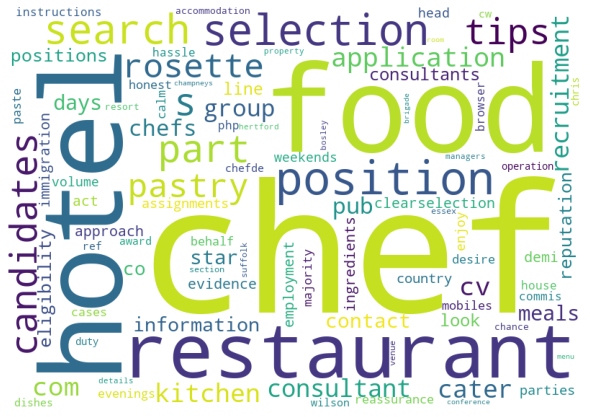

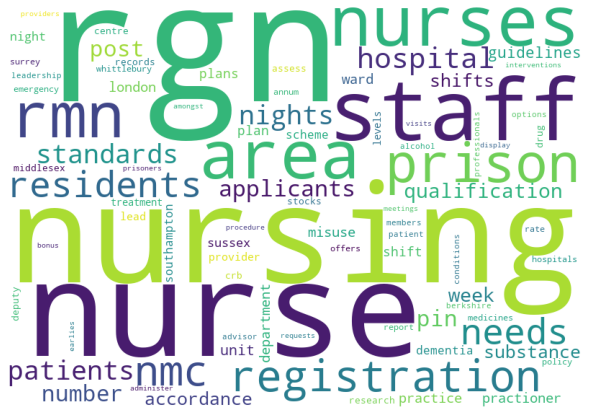

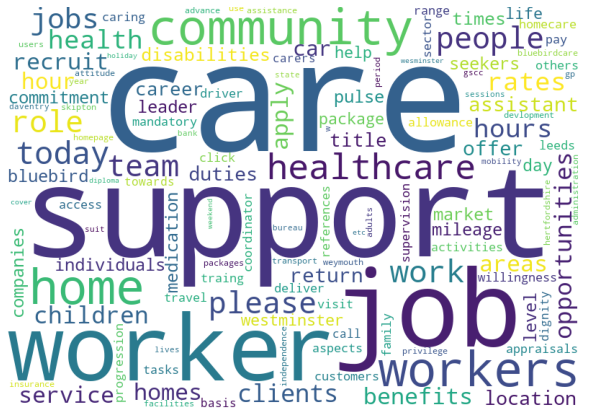

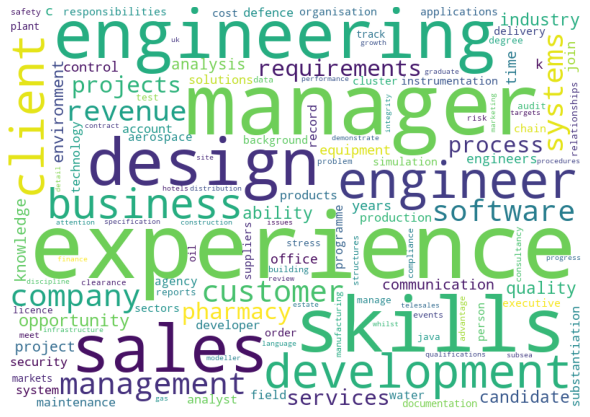

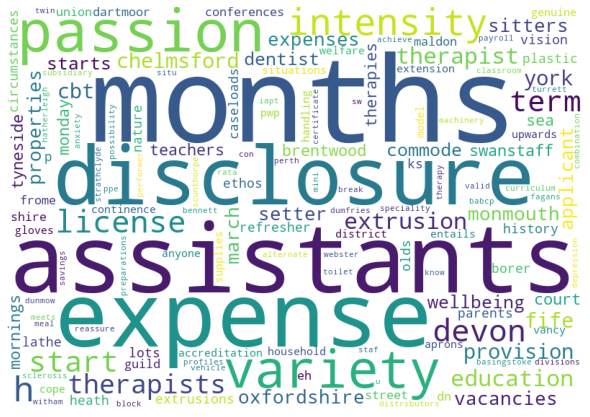

In [16]:
### Top words from LDA
if TopicModelObject.method == 'LDA':
    print("LDA model coherence score is: ", TopicModelObject.get_coherence())

    lda_class_distribution = TopicModelObject.vec['LDA']
    labels = np.argmax(lda_class_distribution, axis=1)

    for k, cluster_word_distribution in TopicModelObject.get_top_words_base(top=200).items():

        cluster_word_distribution_dict = dict()
        for item in cluster_word_distribution:
            cluster_word_distribution_dict[item[0]] = item[1]

        get_wordcloud(dir=TopicModelObject.dir, word_distribution=cluster_word_distribution_dict, topic=k)
        

# Get top words from autoencoder (LDA + Embeddings) and create word clouds on n grams
else:
    grams = 1
    for ng in range(grams):
        topic_words = []
        print("WordClouds for {} grams".format(str(ng + 1)))
        # get topic words for all clusters
        new_token_lists = []
        for i in range(TopicModelObject.k):
            k_sentences = np.array(sentences)[sentence_label_dict[i]]
            ngram_token_with_frequency, token_list = generate_n_gram(k_sentences, n=ng + 1, separator='-',
                                                                     keep_stopwords=False, stem=False,
                                                                     keep_nouns_only=True)

            new_token_lists += token_list
            topic_words.append(ngram_token_with_frequency)

        # remove simliar words from clusters
        print("Coherence Score before cleaning of redundant words")
        print(TopicModelObject.get_coherence(dict_count_to_lol(topic_words), new_token_lists))

        topic_words = clean_topics_from_clusters(topics=topic_words, delete = False)

        print("Coherence Score after cleaning of redundant words")
        print(TopicModelObject.get_coherence(dict_count_to_lol(topic_words), new_token_lists))

        # generate wordclouds
        for i in range(TopicModelObject.k):
            get_wordcloud(topic=i, word_count_dict=topic_words[i], dir=TopicModelObject.dir)

#### 4.1.2 WordCloud using top words from embedding model attention.
Use only when the following embeddings have been used [xlnet, bert, xlm, electra, albert]

In [ ]:
topic_words = []
attention = TopicModelObject.vec['attention']
# get topic words for all clusters
new_token_lists = []
for i in range(TopicModelObject.k):
    #attention vector for the samples belonging to this cluster
    k_attention = np.squeeze(attention[:,[sentence_label_dict[i]],:,:,:]) 
    token_with_frequency, token_list = TopicModelObject.get_top_words_using_attention (layer = 3, 
                                                                                       head = None, top = 100)

    new_token_lists += token_list
    topic_words.append(token_with_frequency)

# remove simliar words from clusters
print("Coherence Score before cleaning of redundant words")
print(TopicModelObject.get_coherence(dict_count_to_lol(topic_words), new_token_lists))

#topic_words = clean_topics_from_clusters(topics=topic_words)

print("Coherence Score after cleaning of redundant words")
print(TopicModelObject.get_coherence(dict_count_to_lol(topic_words), new_token_lists))

# generate wordclouds
for i in range(TopicModelObject.k):
    get_wordcloud(topic=i, word_count_dict=topic_words[i], dir=TopicModelObject.dir)

#### 4.1.3 Get Wordcloud using top words from TF-IDF

Getting wordcloud for topic 0 ...
Getting wordcloud for topic 0. Done!
Getting wordcloud for topic 1 ...
Getting wordcloud for topic 1. Done!
Getting wordcloud for topic 2 ...
Getting wordcloud for topic 2. Done!
Getting wordcloud for topic 3 ...
Getting wordcloud for topic 3. Done!
Getting wordcloud for topic 4 ...
Getting wordcloud for topic 4. Done!


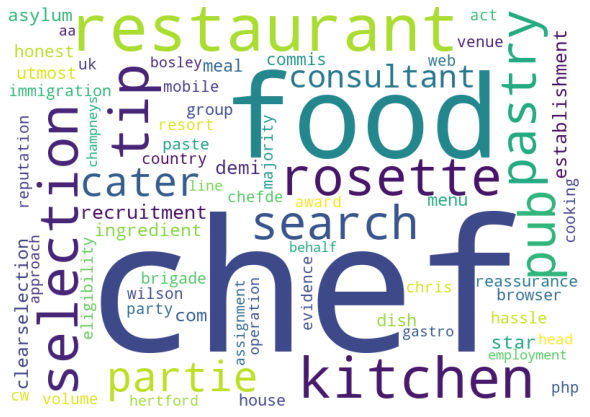

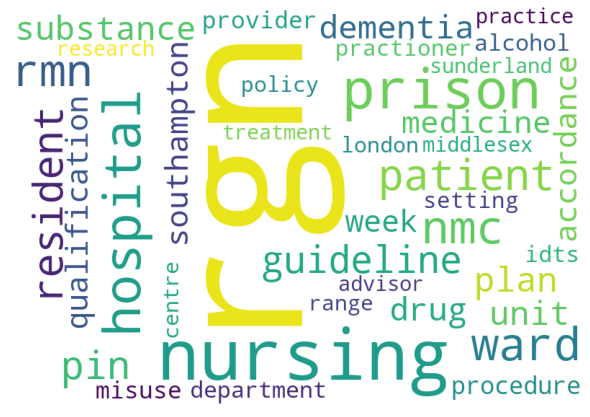

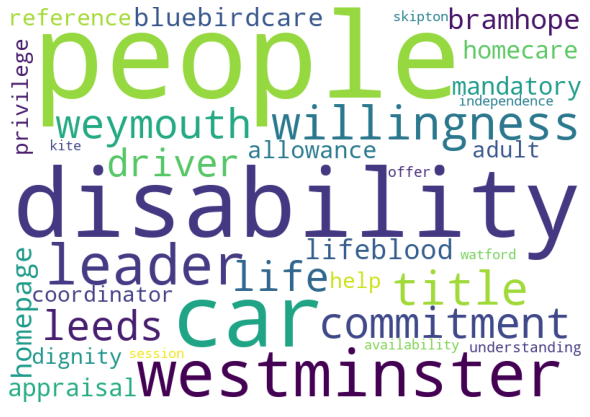

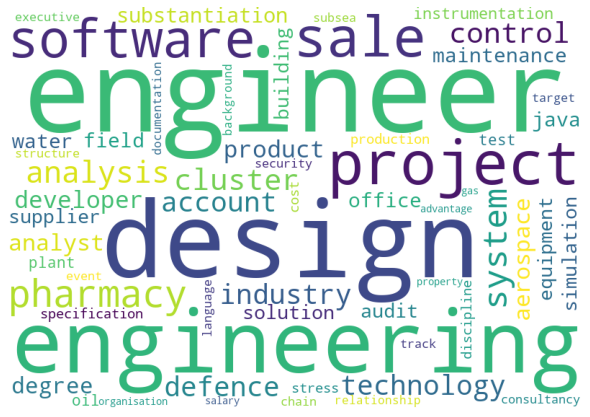

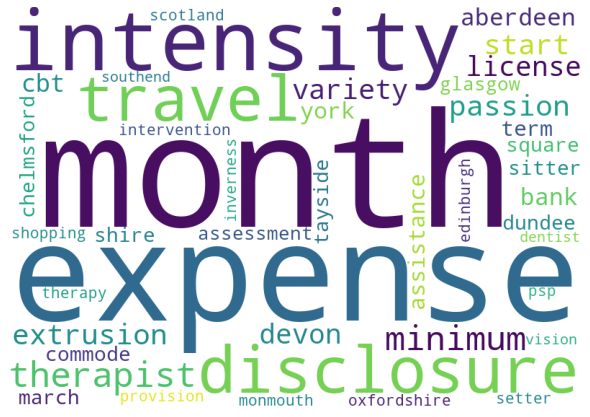

In [18]:
topic_words = TopicModelObject.get_top_words_tfidf(sentence_token=token_lists, sentences=sentences,
                                           sentence_label_dict=sentence_label_dict, top=100)
# remove reduntant words from clusters
topic_words = clean_topics_from_clusters(topics=topic_words, delete = True)


# generate wordclouds
for i in range(TopicModelObject.k):
    get_wordcloud(topic=i, word_count_dict=topic_words[i], dir=TopicModelObject.dir)

## 4.2 Visualization: Scatter plot

Visualize the feature vectors of each employee in a 2d/3d space using plotly

In [ ]:
import plotly.graph_objects as go
from sklearn import preprocessing

In [ ]:
from collections import Counter
#main topics for each cluster
cluster_titles = []

for i in range(TopicModelObject.k):
    k_sentences = np.array(sentences)[sentence_label_dict[i]]
    ngram_token_with_frequency = Counter(generate_n_gram(k_sentences, n=2, separator = '-' ,
                                        keep_stopwords= False, stem=False, keep_nouns_only=False))
    
    
    cluster_title = ', '.join([key for key, value in ngram_token_with_frequency.most_common(6)])
    
    cluster_titles.append(cluster_title)
cluster_titles

In [ ]:
np_sentences = np.array(sentences)

In [ ]:
fig = go.Figure()


for i, cl in enumerate(range(k)):
    
    cluster_df = averaged_employee_features[averaged_employee_features.cluster==cl]
    #plot all the employees belonging to a cluster using a new trace. 
    features = np.stack(cluster_df['feature_vector_2d'].to_numpy())

    employee_titles = []
    # constructing hover text (all objectives belonging to that employee) 
    for emp in cluster_df.index.values:
        
        emp_indices = employee_objective_indices[emp]
        employee_title = '. '.join([objective for objective in np_sentences[emp_indices]])
    
        employee_titles.append(emp + ': ' + employee_title)
        
    fig.add_trace(go.Scattergl(
      x=features[:, 0],
      y=features[:, 1],
      mode='markers',
      showlegend=True,
      text = employee_titles,
      marker=dict(size=8, color=i),
      name="cluster_"+str(cl+1) +": " + cluster_titles[cl]
      ))



fig.update_layout(title='Distribution of employees over clusters in 2d space', legend=dict(
        x=0.6,
        y=1.4,
        traceorder='normal',
        font=dict(
            size=10)))
fig.show()

path = TopicModelObject.dir + '2D_clusters.jpeg'
fig.write_image(path)


In [ ]:
fig = go.Figure()


for i, cl in enumerate(range(k)):
    cluster_df = averaged_employee_features[averaged_employee_features.cluster==cl]

    #plot all the employees belonging to a cluster using a new trace. 
    features = np.stack(cluster_df['feature_vector_2d'].to_numpy())
    
    #normalize the features between 0 and 1
    features_normed = preprocessing.normalize(features)
    # Normalize the features between 0 and 1 before visualization
    min_ = features.min(axis=0)
    max_ = features.max(axis=0)
    features_normed = (features - min_) / (max_ - min_)
    
    employee_titles = []
    # constructing hover text (all objectives belonging to that employee) 
    for emp in cluster_df.index.values:
        
        emp_indices = employee_objective_indices[emp]
        employee_title = '. '.join([objective for objective in np_sentences[emp_indices]])
    
        employee_titles.append(emp + ': ' + employee_title)


    fig.add_trace(go.Scattergl(
      x=features_normed[:, 0],
      y=features_normed[:, 1],
      mode='markers',
      showlegend=True,
      text = employee_titles,
      marker=dict(size=8, color=i),
      name="cluster_"+str(cl+1) +": " + cluster_titles[cl]
    ))



fig.update_layout(title='Distribution of employees over clusters in 2d space - Normalized', legend=dict(
        x=0.6,
        y=1.4,
        traceorder='normal',
        font=dict(
            size=10)))
fig.show()
path = TopicModelObject.dir + '2D_clusters_norm.jpeg'
fig.write_image(path)

In [ ]:
fig = go.Figure()
for i , cl in enumerate(range(k)):
    
    cluster_df = averaged_employee_features[averaged_employee_features.cluster==cl]

    #plot all the employees belonging to a cluster using a new trace. 
    features = np.stack(cluster_df['feature_vector_3d'].to_numpy())
    
    employee_titles = []
    # constructing hover text (all objectives belonging to that employee) 
    for emp in cluster_df.index.values:
        
        emp_indices = employee_objective_indices[emp]
        employee_title = '. '.join([objective for objective in np_sentences[emp_indices]])
    
        employee_titles.append(emp + ': ' + employee_title)


    fig.add_trace(go.Scatter3d(
      x=features[:, 0],
      y=features[:, 1],
      z=features[:, 2],
      mode='markers',
      showlegend=True,
      text = employee_titles,
      marker=dict(size=3, color=i),
      name="cluster_"+str(cl+1) +": " + cluster_titles[cl]
    ))

fig.update_layout(title='Distribution of employees over clusters in 3d Space', legend=dict(
        x=0.6,
        y=1.4,
        traceorder='normal',
        font=dict(
            size=10)))
fig.show()
path = TopicModelObject.dir + '3D_clusters.jpeg'
fig.write_image(path)

In [ ]:
fig = go.Figure()

for i, cl in enumerate(range(k)):
    cluster_df = averaged_employee_features[averaged_employee_features.cluster==cl]

    #plot all the employees belonging to a cluster using a new trace. 
    features = np.stack(cluster_df['feature_vector_3d'].to_numpy())
    
    #normalize the features between 0 and 1
    
    
    min_ = features.min(axis=0)
    max_ = features.max(axis=0)

    features_normed = (features - min_) / (max_ - min_)
    #features_normed = preprocessing.normalize(features)

    
    employee_titles = []
    # constructing hover text (all objectives belonging to that employee) 
    for emp in cluster_df.index.values:
        
        emp_indices = employee_objective_indices[emp]
        employee_title = '. '.join([objective for objective in np_sentences[emp_indices]])
    
        employee_titles.append(emp + ': ' + employee_title)


    fig.add_trace(go.Scatter3d(
      x=features_normed[:, 0],
      y=features_normed[:, 1],
      z=features_normed[:, 2],
      mode='markers',
      showlegend=True,
      text = employee_titles,
      marker=dict(size=3, color=i),
      name="cluster_"+str(cl+1) +": " + cluster_titles[cl]
    ))

fig.update_layout(title='Distribution of employees over clusters in 3d Space - Normalized', legend=dict(
        x=0.6,
        y=1.4,
        traceorder='normal',
        font=dict(
            size=10)))
fig.show()
path = TopicModelObject.dir + '3d_clusters_norm1.jpeg'
fig.write_image(path)

### 4.3 pyLDAvis
This visualization only works on LDA results

In [ ]:
import pyLDAvis
from pyLDAvis import gensim as gs

In [ ]:
id2word = corpora.Dictionary(token_lists)
corpus = [id2word.doc2bow(text) for text in token_lists]

In [ ]:
pyLDAvis.enable_notebook()
vis = gs.prepare(TopicModelObject.ldamodel, corpus, id2word)
vis